Split sizes -> train=600, val=200, test=200


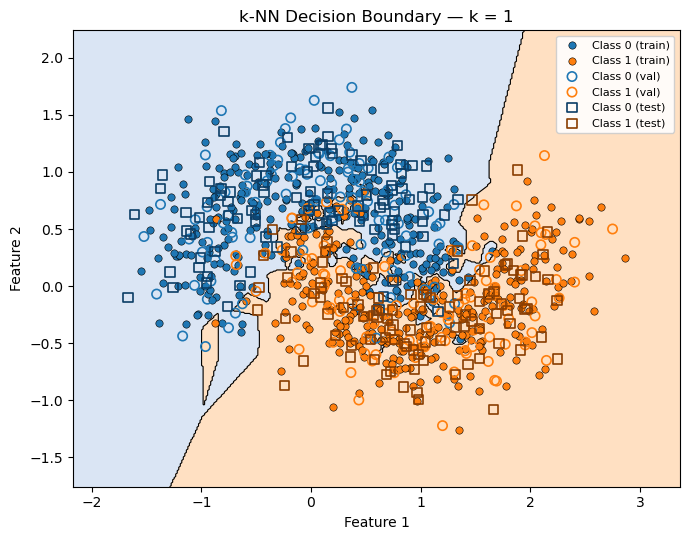

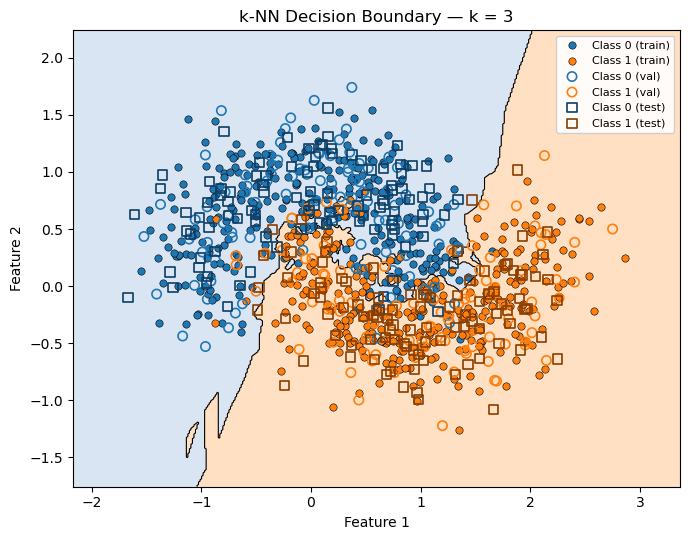

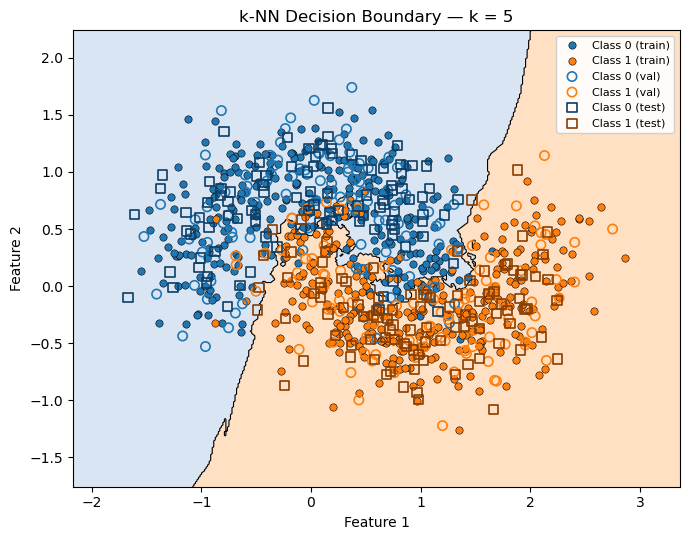

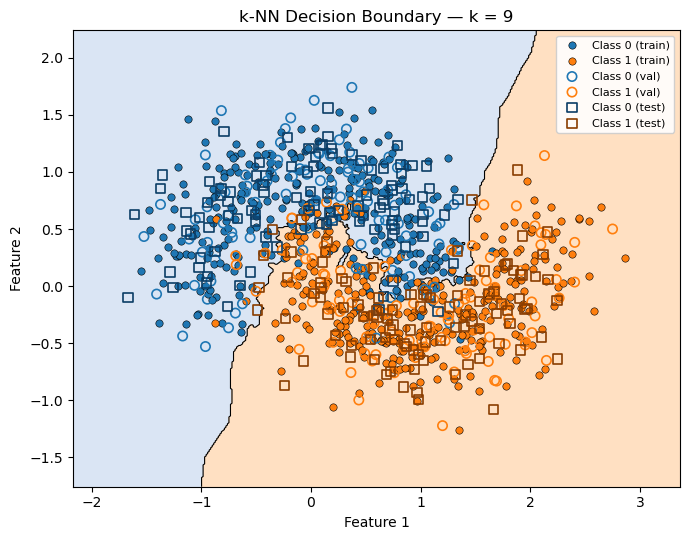

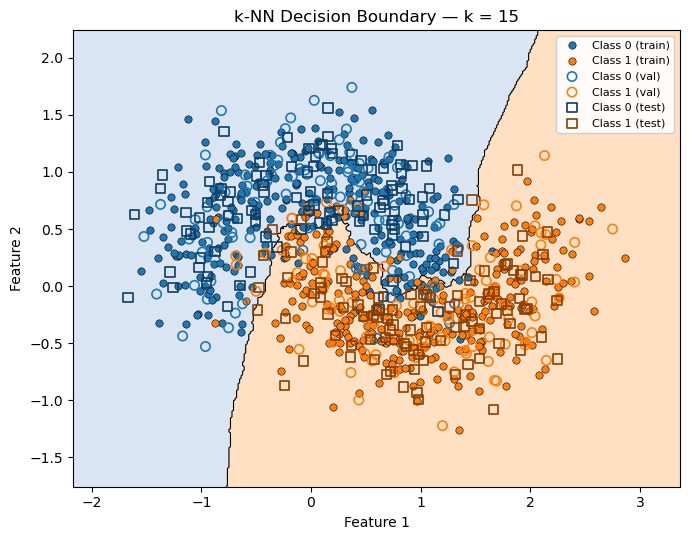

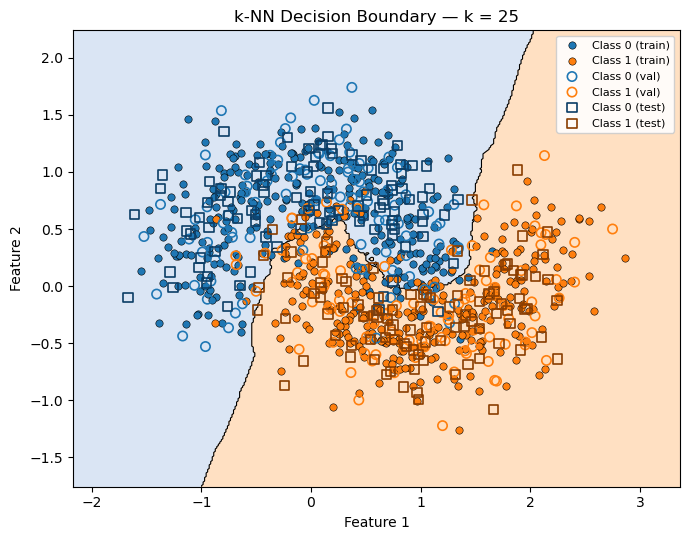

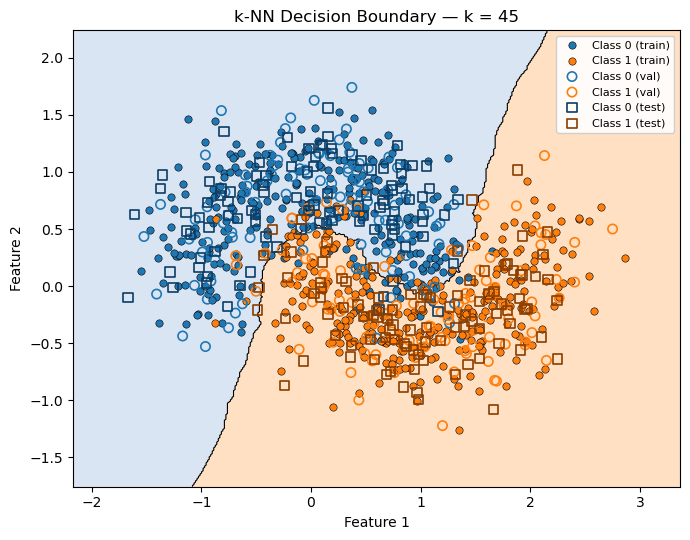

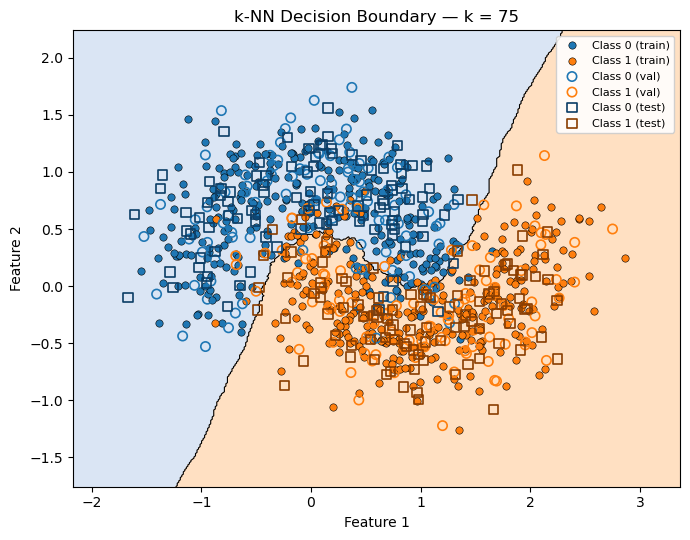

/var/folders/k1/8851q1nj2j3dnxw7hpy7f4f80000gn/T/ipykernel_5958/3951499157.py:186: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-s" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(ks, test_err, "-s", lw=2.0, color="tab:green",


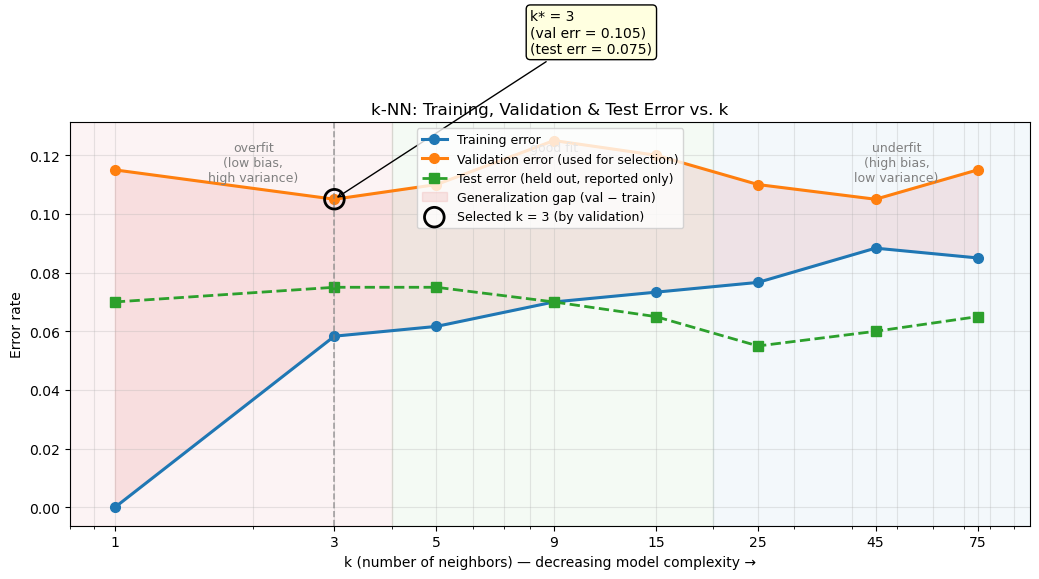

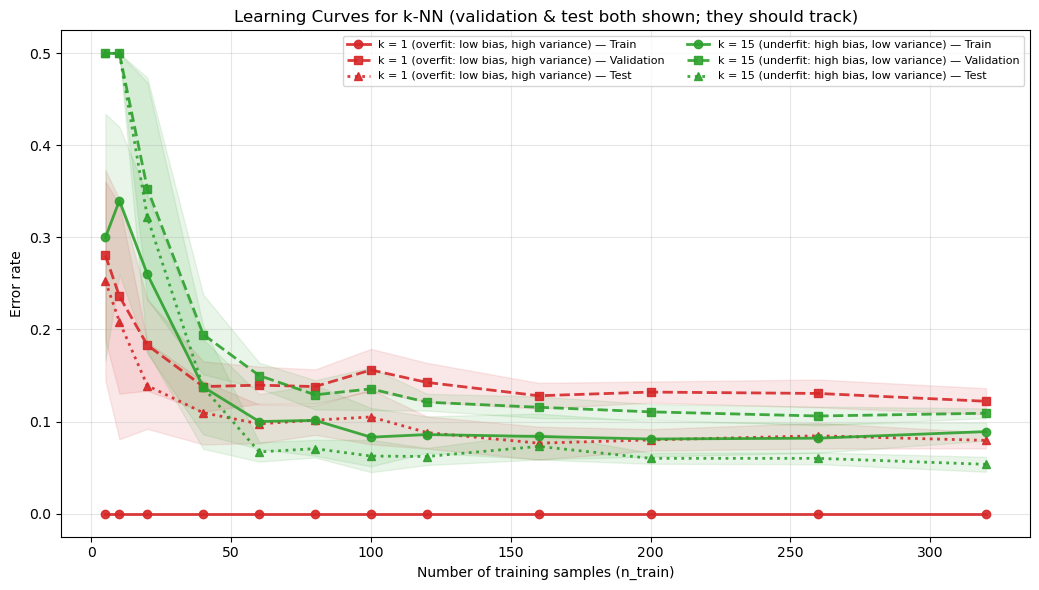


k-NN Classification — Model Complexity Report
  Total dataset      : 1000
  Training size      : 600
  Validation size    : 200  (used to select k)
  Test size          : 200   (held out; reported once)
  Two-moons noise    : 0.3

    k |  Train Err |   Val Err |  Test Err |  Val Gap |  Test Gap
-----------------------------------------------------------------
    1 |     0.0000 |    0.1150 |    0.0700 |   0.1150 |    0.0700
    3 |     0.0583 |    0.1050 |    0.0750 |   0.0467 |    0.0167
    5 |     0.0617 |    0.1100 |    0.0750 |   0.0483 |    0.0133
    9 |     0.0700 |    0.1250 |    0.0700 |   0.0550 |    0.0000
   15 |     0.0733 |    0.1200 |    0.0650 |   0.0467 |   -0.0083
   25 |     0.0767 |    0.1100 |    0.0550 |   0.0333 |   -0.0217
   45 |     0.0883 |    0.1050 |    0.0600 |   0.0167 |   -0.0283
   75 |     0.0850 |    0.1150 |    0.0650 |   0.0300 |   -0.0200

------------------------------------------------------------------------
FINAL TEST REPORT — selected by va

In [2]:
# =============================================================================
# MODEL COMPLEXITY AND K-NEAREST NEIGHBORS CLASSIFICATION
# =============================================================================
#
# Demonstrates underfitting, appropriate fitting, and overfitting on a
# two-moons classification problem using k-NN with varying k.
#
# Data split (three-way, stratified):
#   * TRAIN       -> fit the model
#   * VALIDATION  -> select k
#   * TEST        -> final unbiased estimate of generalization error
#
# Also demonstrates learning curves: how train/validation/test error evolve
# as the number of training samples increases.
#
# Figures produced:
#   1. Decision-boundary plots for k = 1, 3, 5, 9, 15, 25, 45, 75
#   2. Training, validation & test error vs. k  (complexity curve)
#   3. Learning curves: error vs. n_train, for an overfit and an underfit k
#
# Console output:
#   Table of (k, training error, validation error, test error, gap)
#   Final test report for the selected model.
#
# Requirements: numpy, matplotlib, scikit-learn
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# =============================================================================
# 1. REPRODUCIBILITY
# =============================================================================
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

N_TOTAL = 1000
NOISE = 0.30
VAL_FRACTION = 0.20
TEST_FRACTION = 0.20

K_VALUES = [1, 3, 5, 9, 15, 25, 45, 75]
LEARNING_KS = [1, 15]


# =============================================================================
# 2. DATA  (three-way stratified split: train / val / test)
# =============================================================================
X, y = make_moons(n_samples=N_TOTAL, noise=NOISE, random_state=RANDOM_SEED)

# First split off test, then split the rest into train / validation.
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=TEST_FRACTION, random_state=RANDOM_SEED, stratify=y
)
# val fraction of the *remaining* data:
val_frac_of_tmp = VAL_FRACTION / (1.0 - TEST_FRACTION)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=val_frac_of_tmp,
    random_state=RANDOM_SEED, stratify=y_tmp
)

print(f"Split sizes -> train={len(X_train)}, "
      f"val={len(X_val)}, test={len(X_test)}")

# Grid for decision-boundary visualization
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400),
)
grid = np.c_[xx.ravel(), yy.ravel()]

cmap_bg = ListedColormap(["#aec7e8", "#ffbb78"])


# =============================================================================
# 3. FIT AND EVALUATE k-NN FOR A GIVEN k
# =============================================================================
def fit_knn(k):
    """Fit k-NN on train; return model plus train/val/test error rates."""
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    val_acc = accuracy_score(y_val, model.predict(X_val))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    return model, train_acc, val_acc, test_acc


# =============================================================================
# 4. DECISION-BOUNDARY PLOT FOR ONE k
# =============================================================================
def plot_decision_boundary(k, model):
    Z = model.predict(grid).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.contourf(xx, yy, Z, alpha=0.45, cmap=cmap_bg, levels=[-0.5, 0.5, 1.5])
    ax.contour(xx, yy, Z, colors="k", linewidths=0.8, levels=[0.5])

    # Training points (filled circles)
    ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
               s=28, c="#1f77b4", edgecolor="k", linewidth=0.4,
               label="Class 0 (train)", zorder=3)
    ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
               s=28, c="#ff7f0e", edgecolor="k", linewidth=0.4,
               label="Class 1 (train)", zorder=3)

    # Validation points (hollow circles)
    ax.scatter(X_val[y_val == 0, 0], X_val[y_val == 0, 1],
               s=45, facecolor="none", edgecolor="#1f77b4",
               linewidth=1.2, label="Class 0 (val)", zorder=4)
    ax.scatter(X_val[y_val == 1, 0], X_val[y_val == 1, 1],
               s=45, facecolor="none", edgecolor="#ff7f0e",
               linewidth=1.2, label="Class 1 (val)", zorder=4)

    # Test points (hollow squares, distinctly dark edges)
    ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1],
               s=45, marker="s", facecolor="none", edgecolor="#0b3d66",
               linewidth=1.2, label="Class 0 (test)", zorder=4)
    ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1],
               s=45, marker="s", facecolor="none", edgecolor="#8a3d00",
               linewidth=1.2, label="Class 1 (test)", zorder=4)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_title(f"k-NN Decision Boundary — k = {k}")
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
    plt.tight_layout()
    plt.savefig(f"knn_decision_boundary_k{k:02d}.png", dpi=120)
    plt.show()


# =============================================================================
# 5. FIT ALL K VALUES AND PLOT DECISION BOUNDARIES
# =============================================================================
def fit_all_ks(ks):
    results = {}
    for k in ks:
        model, train_acc, val_acc, test_acc = fit_knn(k)
        results[k] = {
            "model": model,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "test_acc": test_acc,
        }
        plot_decision_boundary(k, model)
    return results


results = fit_all_ks(K_VALUES)

ks_arr = np.array(K_VALUES)
train_err = np.array([1 - results[k]["train_acc"] for k in K_VALUES])
val_err = np.array([1 - results[k]["val_acc"] for k in K_VALUES])
test_err = np.array([1 - results[k]["test_acc"] for k in K_VALUES])
gap_val = val_err - train_err
gap_test = test_err - train_err


# =============================================================================
# 6. COMPLEXITY CURVE: ERROR vs. k  (train, val, test)
# =============================================================================
def plot_error_vs_k(ks, train_err, val_err, test_err, best_k=None):
    ks = np.asarray(ks)
    train_err = np.asarray(train_err)
    val_err = np.asarray(val_err)
    test_err = np.asarray(test_err)

    fig, ax = plt.subplots(figsize=(10.5, 6))

    ax.plot(ks, train_err, "-o", lw=2.2, color="tab:blue",
            markersize=7, label="Training error")
    ax.plot(ks, val_err, "-o", lw=2.2, color="tab:orange",
            markersize=7, label="Validation error (used for selection)")
    ax.plot(ks, test_err, "-s", lw=2.0, color="tab:green",
            markersize=7, linestyle="--",
            label="Test error (held out, reported only)")

    ax.fill_between(ks, train_err, val_err,
                    where=(val_err >= train_err),
                    color="tab:red", alpha=0.10,
                    label="Generalization gap (val − train)")

    if best_k is not None:
        idx = int(np.where(ks == best_k)[0][0])
        ax.axvline(best_k, color="gray", lw=1.2, linestyle="--", alpha=0.7)
        ax.scatter([best_k], [val_err[idx]], s=200, facecolor="none",
                   edgecolor="black", linewidth=2, zorder=5,
                   label=f"Selected k = {best_k} (by validation)")
        ax.annotate(f"k* = {best_k}\n(val err = {val_err[idx]:.3f})\n"
                    f"(test err = {test_err[idx]:.3f})",
                    xy=(best_k, val_err[idx]),
                    xytext=(best_k + 5, val_err[idx] + 0.05),
                    fontsize=10,
                    arrowprops=dict(arrowstyle="->", color="black", lw=1),
                    bbox=dict(boxstyle="round,pad=0.3",
                              facecolor="lightyellow", edgecolor="black"))

    ax.axvspan(0.5, 4, color="tab:red", alpha=0.05)
    ax.axvspan(4, 20, color="tab:green", alpha=0.05)
    ax.axvspan(20, 100, color="tab:blue", alpha=0.05)
    ymax = ax.get_ylim()[1]
    ax.text(2, ymax * 0.95, "overfit\n(low bias,\nhigh variance)",
            ha="center", va="top", fontsize=9, color="gray")
    ax.text(9, ymax * 0.95, "good fit",
            ha="center", va="top", fontsize=9, color="gray")
    ax.text(50, ymax * 0.95, "underfit\n(high bias,\nlow variance)",
            ha="center", va="top", fontsize=9, color="gray")

    ax.set_xscale("log")
    ax.set_xticks(ks)
    ax.set_xticklabels([str(k) for k in ks])
    ax.set_xlim(ks.min() * 0.8, ks.max() * 1.3)
    ax.set_xlabel("k (number of neighbors) — decreasing model complexity →")
    ax.set_ylabel("Error rate")
    ax.set_title("k-NN: Training, Validation & Test Error vs. k")
    ax.grid(True, alpha=0.3, which="both")
    ax.legend(loc="upper center", fontsize=9)
    plt.tight_layout()
    plt.savefig("knn_error_vs_k.png", dpi=120)
    plt.show()


# =============================================================================
# 7. LEARNING CURVES: HOW ERROR CHANGES WITH THE NUMBER OF SAMPLES
# =============================================================================
def learning_curve_for_k(k, n_train_sizes, n_repeats=10):
    """For each n_train, average train/val/test error over random subsets."""
    avg_train_err, avg_val_err, avg_test_err = [], [], []
    std_train_err, std_val_err, std_test_err = [], [], []

    for n in n_train_sizes:
        train_errors, val_errors, test_errors = [], [], []
        for _ in range(n_repeats):
            idx = rng.choice(len(X_train), size=n, replace=False)
            Xs, ys = X_train[idx], y_train[idx]

            model = KNeighborsClassifier(n_neighbors=min(k, n))
            model.fit(Xs, ys)

            train_errors.append(1 - accuracy_score(ys, model.predict(Xs)))
            val_errors.append(1 - accuracy_score(y_val, model.predict(X_val)))
            test_errors.append(1 - accuracy_score(y_test, model.predict(X_test)))

        avg_train_err.append(np.mean(train_errors))
        avg_val_err.append(np.mean(val_errors))
        avg_test_err.append(np.mean(test_errors))
        std_train_err.append(np.std(train_errors))
        std_val_err.append(np.std(val_errors))
        std_test_err.append(np.std(test_errors))

    return (np.array(avg_train_err), np.array(avg_val_err), np.array(avg_test_err),
            np.array(std_train_err), np.array(std_val_err), np.array(std_test_err))


def plot_learning_curves(ks, n_train_sizes):
    fig, ax = plt.subplots(figsize=(10.5, 6))

    base_colors = {ks[0]: "tab:red", ks[1]: "tab:green"}
    labels = {
        ks[0]: f"k = {ks[0]} (overfit: low bias, high variance)",
        ks[1]: f"k = {ks[1]} (underfit: high bias, low variance)",
    }

    for k in ks:
        tr, va, te, tr_s, va_s, te_s = learning_curve_for_k(k, n_train_sizes)
        c = base_colors[k]

        # Training (solid circles)
        ax.plot(n_train_sizes, tr, "-o", lw=2, color=c,
                label=f"{labels[k]} — Train", alpha=0.9)
        ax.fill_between(n_train_sizes, tr - tr_s, tr + tr_s,
                        color=c, alpha=0.10)

        # Validation (dashed squares)
        ax.plot(n_train_sizes, va, "--s", lw=2, color=c,
                label=f"{labels[k]} — Validation", alpha=0.9)
        ax.fill_between(n_train_sizes, va - va_s, va + va_s,
                        color=c, alpha=0.10)

        # Test (dotted triangles)
        ax.plot(n_train_sizes, te, ":^", lw=2, color=c,
                label=f"{labels[k]} — Test", alpha=0.9)
        ax.fill_between(n_train_sizes, te - te_s, te + te_s,
                        color=c, alpha=0.10)

    ax.set_xlabel("Number of training samples (n_train)")
    ax.set_ylabel("Error rate")
    ax.set_title("Learning Curves for k-NN "
                 "(validation & test both shown; they should track)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig("knn_learning_curves.png", dpi=120)
    plt.show()


# =============================================================================
# 8. REPORTING
# =============================================================================
def print_table(ks, train_err, val_err, test_err):
    header = (f"{'k':>5} | {'Train Err':>10} | {'Val Err':>9} | "
              f"{'Test Err':>9} | {'Val Gap':>8} | {'Test Gap':>9}")
    print(header)
    print("-" * len(header))
    for k, tr, va, te in zip(ks, train_err, val_err, test_err):
        print(f"{k:>5d} | {tr:>10.4f} | {va:>9.4f} | {te:>9.4f} | "
              f"{va - tr:>8.4f} | {te - tr:>9.4f}")


def select_best_k(ks, val_err):
    ks = np.asarray(ks)
    return int(ks[int(np.argmin(val_err))])


# =============================================================================
# 9. MAIN
# =============================================================================
def main():
    # ---- Selection: by validation error only ----
    best_k = select_best_k(K_VALUES, val_err)
    best_idx = int(np.where(ks_arr == best_k)[0][0])

    # ---- Complexity curve ----
    plot_error_vs_k(ks_arr, train_err, val_err, test_err, best_k=best_k)

    # ---- Learning curves (include test) ----
    n_train_sizes = [5, 10, 20, 40, 60, 80, 100, 120, 160, 200, 260, 320]
    n_train_sizes = [n for n in n_train_sizes if n <= len(X_train)]
    plot_learning_curves(LEARNING_KS, n_train_sizes)

    # ---- Console report ----
    print()
    print("=" * 72)
    print("k-NN Classification — Model Complexity Report")
    print("=" * 72)
    print(f"  Total dataset      : {N_TOTAL}")
    print(f"  Training size      : {len(X_train)}")
    print(f"  Validation size    : {len(X_val)}  (used to select k)")
    print(f"  Test size          : {len(X_test)}   (held out; reported once)")
    print(f"  Two-moons noise    : {NOISE}")
    print()
    print_table(K_VALUES, train_err, val_err, test_err)

    print()
    print("-" * 72)
    print("FINAL TEST REPORT — selected by validation, evaluated on test")
    print("-" * 72)
    print(f"  Selected k (lowest validation error) : {best_k}")
    print(f"  Training error of selected model     : {train_err[best_idx]:.4f}")
    print(f"  Validation error of selected model   : {val_err[best_idx]:.4f}")
    print(f"  TEST error of selected model         : {test_err[best_idx]:.4f}")
    print(f"  |Val − Test| error difference        : "
          f"{abs(val_err[best_idx] - test_err[best_idx]):.4f}")
    print("  (A small difference means validation is a reliable proxy for test.)")

    print()
    print("Learning-curve summary (averaged over repeats):")
    print(f"  k = {LEARNING_KS[0]:>2} (overfit) : train err ≈ 0; val & test "
          f"err track each other and drop as n grows.")
    print(f"  k = {LEARNING_KS[1]:>2} (underfit): train, val & test err all "
          f"plateau at a high value.")

    print()
    print("Educational interpretation:")
    print("  * Three roles of the data:")
    print("      - TRAIN      -> fit the model.")
    print("      - VALIDATION -> choose k (no test peeking).")
    print("      - TEST       -> one-shot, unbiased estimate of generalization.")
    print("  * Small k (e.g. 1)     -> low bias, high variance -> OVERFIT.")
    print("  * Medium k             -> balance -> GOOD FIT.")
    print("  * Large k              -> high bias, low variance -> UNDERFIT.")
    print("  * Validation and test error curves should track closely.")
    print("    Large, persistent divergence would indicate a distribution")
    print("    shift or an unlucky split — a red flag worth investigating.")
    print("  * As n_train increases:")
    print("      - For overfit models, the gap shrinks; val and test error fall.")
    print("      - For underfit models, all errors plateau; more data cannot")
    print("        fix a bias problem.")


if __name__ == "__main__":
    main()